# 04 · Reconciliation: making 164 forecasts add up

**Question:** does forcing trusts → ICBs → regions → England to add up cost accuracy, or improve it?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nhsae import viz
from nhsae.backtest import load
from nhsae.config import LEVELS, RESULTS
from nhsae.forecast import best_config

viz.set_style()
H, y = load("attendances")
print(f"S is {H.S.shape[0]} × {H.S.shape[1]}: " + ", ".join(f"{(H.levels == lvl).sum()} {lvl}" for lvl in LEVELS))

S is 164 × 120: 1 England, 7 Region, 36 ICB, 120 Trust


## 1. How incoherent are base forecasts?
Base forecasts from the backtest, before reconciliation: how far is the sum of trust forecasts from
the England forecast?

In [2]:
model, recon, covid = best_config("attendances")
b = pd.read_parquet(RESULTS / f"backtest_attendances_{covid}.parquet",
                    columns=["origin", "model", "recon", "h", "series", "level", "forecast", "ase"])
base = b[(b.model == model) & (b.recon == "base")]
eng = base[base.series == "England"].set_index(["origin", "h"]).forecast
trusts = base[base.level == "Trust"].groupby(["origin", "h"]).forecast.sum()
gap = (trusts / eng - 1)
print(f"Σ trust base forecasts vs England base forecast: mean gap {gap.mean():+.2%}, range {gap.min():+.2%} to {gap.max():+.2%}")

rec = b[(b.model == model) & (b.recon == recon)]
eng_r = rec[rec.series == "England"].set_index(["origin", "h"]).forecast
tr_r = rec[rec.level == "Trust"].groupby(["origin", "h"]).forecast.sum()
print(f"after {recon}: max |gap| = {(tr_r / eng_r - 1).abs().max():.2e}")

Σ trust base forecasts vs England base forecast: mean gap +0.42%, range -2.32% to +2.43%
after mint_shrink: max |gap| = 1.44e-15


A gap of a percent or two at England level is 15,000–30,000 attendances a month: enough for national and
local plans to disagree.

## 2. Accuracy by reconciliation method

level,England,Region,ICB,Trust
recon,,,,
base,0.441,0.478,0.627,0.665
bu,0.420,0.479,0.619,0.665
td,0.441,0.505,0.704,0.756
ols,0.436,0.489,0.644,0.689
wls_struct,0.421,0.473,0.624,0.671
mint_shrink,0.396,0.459,0.613,0.662


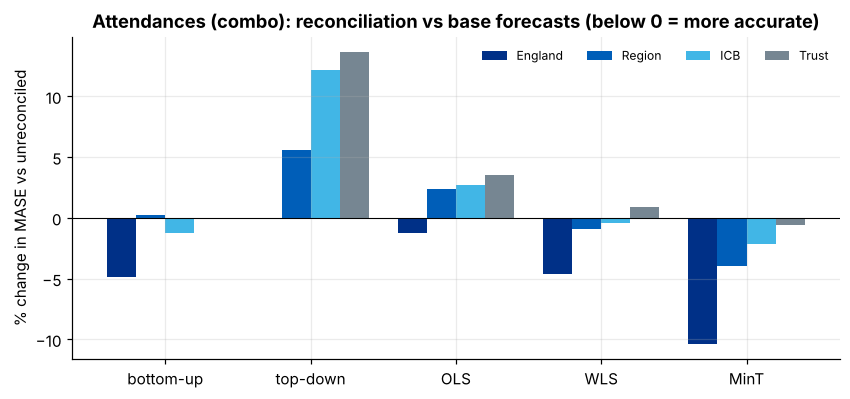

In [3]:
summ = pd.read_csv(RESULTS / "backtest_summary_attendances.csv")
s = summ[(summ.covid == covid) & (summ.model == model)].pivot_table(index="recon", columns="level", values="MASE")[LEVELS]
order = ["base", "bu", "td", "ols", "wls_struct", "mint_shrink"]
s = s.loc[order]
rel = 100 * (s / s.loc["base"] - 1)
fig, ax = plt.subplots(figsize=(9, 3.8))
w = 0.2
for i, lvl in enumerate(LEVELS):
    ax.bar(np.arange(5) + (i - 1.5) * w, rel.loc[order[1:], lvl], width=w, color=viz.LEVEL_COLOURS[lvl], label=lvl)
ax.axhline(0, color="black", lw=0.7)
ax.set_xticks(range(5), ["bottom-up", "top-down", "OLS", "WLS", "MinT"])
ax.set_ylabel("% change in MASE vs unreconciled")
ax.set_title(f"Attendances ({model}): reconciliation vs base forecasts (below 0 = more accurate)")
ax.legend(ncol=4, fontsize=8)
viz.save(fig, "04_reconciliation_gain")
s.round(3)

In [4]:
summ_a = pd.read_csv(RESULTS / "backtest_summary_emergency_admissions.csv")
ma, ra, ca = best_config("emergency_admissions")
sa = summ_a[(summ_a.covid == ca) & (summ_a.model == ma)].pivot_table(index="recon", columns="level", values="MASE")[LEVELS]
sa.loc[order].round(3)

level,England,Region,ICB,Trust
recon,,,,
base,0.415,0.555,0.768,0.885
bu,0.398,0.533,0.763,0.885
td,0.415,0.587,0.842,0.980
ols,0.414,0.559,0.785,0.916
wls_struct,0.403,0.544,0.771,0.901
mint_shrink,0.377,0.522,0.752,0.882


**Top-down is the method that hurts**: splitting England by fixed historical shares misses trusts whose
demand is growing faster or slower than average (notebook 02 showed trust growth ranging from about −2% to +8%).
MinT uses the base forecasts' error covariance to decide how much to move each series.

## 3. The live, coherent forecast

England, next 12 months: 18,156,087 Type 1 attendances (+3.7% on the last 12 months)


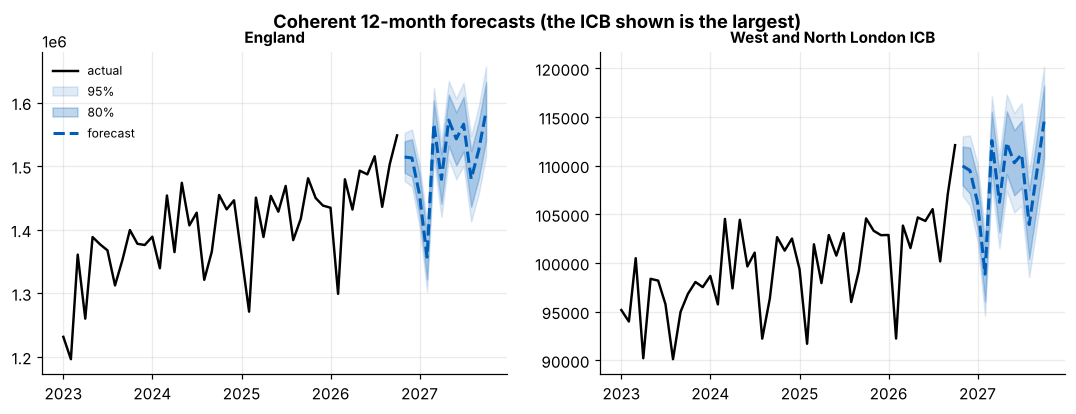

In [5]:
fc = pd.read_csv(RESULTS / "forecast_attendances.csv", parse_dates=["month"])
hist = pd.read_csv(RESULTS / "history_attendances.csv", parse_dates=["month"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
icb_id = fc[fc.level == "ICB"].groupby("series").forecast.sum().idxmax()
for ax, sid in zip(axes, ["England", icb_id]):
    h = hist[(hist.series == sid) & (hist.month >= "2023-01-01")]
    f = fc[fc.series == sid]
    ax.plot(h.month, h.actual, color="black", lw=1.6, label="actual")
    ax.fill_between(f.month, f.lo95, f.hi95, color=viz.NHS_BLUE, alpha=0.12, label="95%")
    ax.fill_between(f.month, f.lo80, f.hi80, color=viz.NHS_BLUE, alpha=0.25, label="80%")
    ax.plot(f.month, f.forecast, color=viz.NHS_BLUE, lw=2, ls="--", label="forecast")
    ax.set_title(f["name"].iloc[0], fontsize=10)
axes[0].legend(fontsize=8)
fig.suptitle("Coherent 12-month forecasts (the ICB shown is the largest)", fontweight="bold")
viz.save(fig, "04_forecast_example")

eng_f = fc[fc.series == "England"].forecast.sum()
eng_ly = hist[(hist.series == "England")].actual.iloc[-12:].sum()
print(f"England, next 12 months: {eng_f:,.0f} Type 1 attendances ({eng_f / eng_ly - 1:+.1%} on the last 12 months)")